# Task 1 (C) — Model Training, Hyperparameter Tuning & Experiments

**Task:** one-step-ahead forecast of hourly `traffic_volume`. For each hour *t* the model sees:
* **calendar** at *t* (hour, weekday, month, weekend, holiday, cyclical encodings)
* **weather** at *t* (temperature, rain, snow, clouds, weather one-hots). In deployment this is the next-hour weather forecast; in `scripts/predict.py` it is the latest observed weather (persistence).
* **lagged traffic** — lags 1, 2, 3, 24 and 168 h
* **moving averages** of past traffic — 3 h, 24 h, 168 h means and the 24 h standard deviation

All lag and rolling features are shifted by at least one hour, so there is **no look-ahead leakage** (see `src/preprocessing.py`).

**Validation design**
* **Chronological hold-out test set:** 1 Jan 2018 → 30 Sep 2018 (never used for tuning or model selection).
* **Tuning:** `TimeSeriesSplit` (4 expanding folds) on the training period only. Each fold trains on the past and validates on the following block, so no fold looks into the future.
* **Model selection** uses the **cross-validated MAE**. Test metrics are only reported, never used to pick.
* **Metrics:** MAE (vehicles/hour, easy to explain), RMSE (punishes large rush-hour misses), R², and WAPE = Σ|error| / Σ actual. MAPE is avoided because night-time volumes near zero make it explode.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from scipy.stats import randint, uniform, loguniform

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from src import preprocessing as pp
from src.config import RAW_DATA_PATH, MODEL_PATH, MODEL_METADATA_PATH, ROOT_DIR
from src.plotting import apply_style, save, SERIES, NEUTRAL, TEXT_SECONDARY

apply_style()
RANDOM_STATE = 42

## 1. Data and chronological split

In [2]:
data = pp.preprocess(pp.load_raw(RAW_DATA_PATH))      # same pipeline as notebook 01 / predict.py
FEATURES = pp.FEATURE_COLUMNS
TARGET = pp.TARGET
TEST_START = "2018-01-01"

train = data[data.index < TEST_START]
test = data[data.index >= TEST_START]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {train.index.min():%Y-%m-%d} -> {train.index.max():%Y-%m-%d}  ({len(train):,} rows)")
print(f"Test:  {test.index.min():%Y-%m-%d} -> {test.index.max():%Y-%m-%d}  ({len(test):,} rows)")
print(f"{len(FEATURES)} features:", FEATURES)

tscv = TimeSeriesSplit(n_splits=4)
for i, (a, b) in enumerate(tscv.split(X_train), 1):
    print(f"  CV fold {i}: train {X_train.index[a[0]]:%Y-%m} -> {X_train.index[a[-1]]:%Y-%m}, "
          f"validate {X_train.index[b[0]]:%Y-%m} -> {X_train.index[b[-1]]:%Y-%m}")

Train: 2012-10-09 -> 2017-12-31  (30,190 rows)
Test:  2018-01-01 -> 2018-09-30  (6,378 rows)
33 features: ['hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_clear', 'weather_clouds', 'weather_drizzle', 'weather_fog', 'weather_haze', 'weather_mist', 'weather_rain', 'weather_smoke', 'weather_snow', 'weather_squall', 'weather_thunderstorm', 'lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_168', 'roll_mean_3', 'roll_mean_24', 'roll_mean_168', 'roll_std_24']
  CV fold 1: train 2012-10 -> 2013-11, validate 2013-11 -> 2015-10
  CV fold 2: train 2012-10 -> 2015-10, validate 2015-10 -> 2016-07
  CV fold 3: train 2012-10 -> 2016-07, validate 2016-07 -> 2017-04
  CV fold 4: train 2012-10 -> 2017-04, validate 2017-04 -> 2017-12


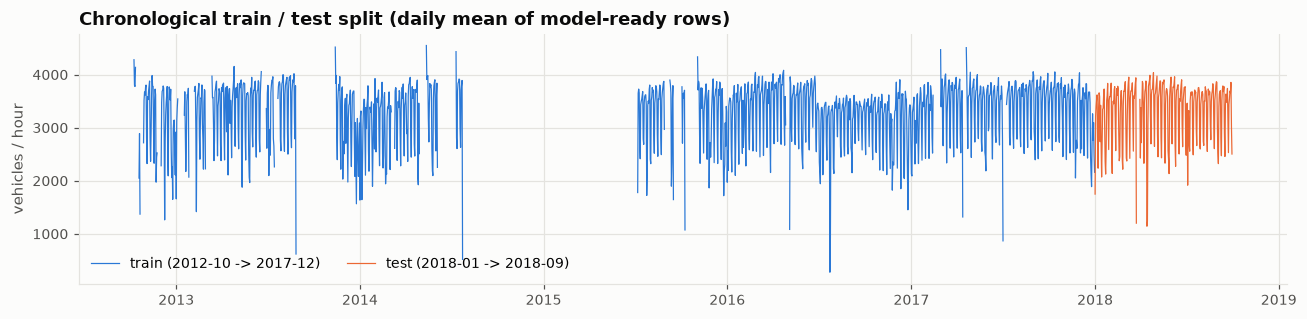

In [3]:
fig, ax = plt.subplots(figsize=(12, 3))
daily = data[TARGET].resample("D").mean()
ax.plot(daily[daily.index < TEST_START], color=SERIES[0], linewidth=0.8, label="train (2012-10 -> 2017-12)")
ax.plot(daily[daily.index >= TEST_START], color=SERIES[1], linewidth=0.8, label="test (2018-01 -> 2018-09)")
ax.set_title("Chronological train / test split (daily mean of model-ready rows)")
ax.set_ylabel("vehicles / hour"); ax.legend(loc="lower left", ncol=2)
fig.tight_layout(); save(fig, "m1_train_test_split"); plt.show()

## 2. Experiment helpers

In [4]:
results = []
predictions = {}

def wape(y, p):
    return np.abs(y - p).sum() / np.abs(y).sum()

def cv_mae(model, X, y):
    # Mean MAE across the 4 time-series folds (training period only).
    scores = cross_val_score(model, X, y, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=1)
    return -scores.mean()

def record(exp_id, name, model, features, params, tuning, cv_score, fit_seconds, preds):
    predictions[exp_id] = preds
    results.append({
        "exp": exp_id, "model": name, "features": features, "hyperparameters": params,
        "tuning": tuning, "cv_mae": round(cv_score, 1) if cv_score is not None else None,
        "test_mae": round(mean_absolute_error(y_test, preds), 1),
        "test_rmse": round(mean_squared_error(y_test, preds) ** 0.5, 1),
        "test_r2": round(r2_score(y_test, preds), 4),
        "test_wape": round(wape(y_test, preds) * 100, 2),
        "fit_s": round(fit_seconds, 1),
    })
    r = results[-1]
    print(f"{exp_id} {name:<28} CV MAE={r['cv_mae']}  test MAE={r['test_mae']}  RMSE={r['test_rmse']}  R2={r['test_r2']}")

## 3. Experiments
### E1 — Seasonal-naive baseline (no training)
Forecast = traffic at the same hour last week (`lag_168`). This was the best single predictor in EDA Q3, so it is the bar to beat.

In [5]:
naive_cv = np.mean([mean_absolute_error(y_train.iloc[b], X_train["lag_168"].iloc[b]) for _, b in tscv.split(X_train)])
record("E1", "Seasonal naive (lag 168 h)", None, "lag_168 only", "-", "none", naive_cv, 0, X_test["lag_168"].values)

E1 Seasonal naive (lag 168 h)   CV MAE=352.9  test MAE=340.2  RMSE=651.2  R2=0.8911


### E2 — Linear Regression (all features)
A transparent linear baseline. Features are standardised so the coefficients are comparable.

In [6]:
lin = make_pipeline(StandardScaler(), LinearRegression())
t = time.time(); lin.fit(X_train, y_train); fit_s = time.time() - t
record("E2", "Linear Regression", lin, "all 33", "defaults", "none", cv_mae(lin, X_train, y_train), fit_s, lin.predict(X_test))

E2 Linear Regression            CV MAE=295.2  test MAE=281.8  RMSE=397.7  R2=0.9594


### E3 — Ridge Regression, tuned
Grid search over the L2 penalty `alpha` with `TimeSeriesSplit`.

In [7]:
ridge_search = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                            {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                            cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
t = time.time(); ridge_search.fit(X_train, y_train); fit_s = time.time() - t
print("Best alpha:", ridge_search.best_params_)
display(pd.DataFrame(ridge_search.cv_results_)[["param_ridge__alpha", "mean_test_score"]].assign(cv_mae=lambda d: -d.mean_test_score).drop(columns="mean_test_score"))
record("E3", "Ridge (tuned)", ridge_search.best_estimator_, "all 33", str(ridge_search.best_params_),
       "GridSearchCV, 6 values x 4 folds", -ridge_search.best_score_, fit_s, ridge_search.predict(X_test))

Best alpha: {'ridge__alpha': 10}


,param_ridge__alpha,cv_mae
0,0.01,295.161449
1,0.10,295.155729
2,1.00,295.099721
3,10.00,294.692245
4,100.00,296.244959
5,1000.00,325.445581


E3 Ridge (tuned)                CV MAE=294.7  test MAE=281.7  RMSE=398.0  R2=0.9593


### E4 — Random Forest, default hyperparameters

In [8]:
rf = RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE)
t = time.time(); rf.fit(X_train, y_train); fit_s = time.time() - t
record("E4", "Random Forest (default)", rf, "all 33", "n_estimators=150, others default", "none",
       cv_mae(rf, X_train, y_train), fit_s, rf.predict(X_test))

E4 Random Forest (default)      CV MAE=184.4  test MAE=146.4  RMSE=231.4  R2=0.9862


### E5 — Random Forest, tuned
Randomised search over tree depth, leaf size, feature subsampling and bootstrap sample size.

In [9]:
rf_space = {
    "n_estimators": [150, 250],
    "max_depth": [12, 18, 24, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [0.33, 0.5, 0.75, 1.0],
    "max_samples": [0.5, 0.75, None],
}
rf_search = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE), rf_space,
                               n_iter=8, cv=tscv, scoring="neg_mean_absolute_error",
                               random_state=RANDOM_STATE, n_jobs=1)
t = time.time(); rf_search.fit(X_train, y_train); fit_s = time.time() - t
best_rf_params = {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in rf_search.best_params_.items()}
print("Best params:", best_rf_params)
record("E5", "Random Forest (tuned)", rf_search.best_estimator_, "all 33", str(best_rf_params),
       "RandomizedSearchCV, 8 configs x 4 folds", -rf_search.best_score_, fit_s, rf_search.predict(X_test))

Best params: {'n_estimators': 150, 'min_samples_leaf': 2, 'max_samples': None, 'max_features': 0.33, 'max_depth': 18}
E5 Random Forest (tuned)        CV MAE=173.8  test MAE=140.0  RMSE=219.4  R2=0.9876


### E6 — Histogram Gradient Boosting, default hyperparameters
Gradient-boosted trees (LightGBM-style histogram binning). Fast on tens of thousands of rows, and models the non-linear hour × weekday × lag interactions.

In [10]:
hgb = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
t = time.time(); hgb.fit(X_train, y_train); fit_s = time.time() - t
record("E6", "HistGradientBoosting (default)", hgb, "all 33", "learning_rate=0.1, max_iter=100, max_leaf_nodes=31",
       "none", cv_mae(hgb, X_train, y_train), fit_s, hgb.predict(X_test))

E6 HistGradientBoosting (default) CV MAE=181.7  test MAE=149.7  RMSE=229.3  R2=0.9865


### E7 — Histogram Gradient Boosting, tuned
Randomised search (25 configurations × 4 time-series folds) over learning rate, number of boosting rounds, tree size, leaf size and L2 regularisation.

In [11]:
hgb_space = {
    "learning_rate": loguniform(0.02, 0.2),
    "max_iter": randint(200, 1000),
    "max_leaf_nodes": randint(15, 128),
    "min_samples_leaf": randint(10, 80),
    "l2_regularization": loguniform(1e-3, 10),
    "max_features": uniform(0.5, 0.5),
}
hgb_search = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=RANDOM_STATE), hgb_space,
                                n_iter=25, cv=tscv, scoring="neg_mean_absolute_error",
                                random_state=RANDOM_STATE, n_jobs=-1)
t = time.time(); hgb_search.fit(X_train, y_train); fit_s = time.time() - t
best_hgb_params = {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v)) for k, v in hgb_search.best_params_.items()}
print("Best params:", best_hgb_params)
record("E7", "HistGradientBoosting (tuned)", hgb_search.best_estimator_, "all 33", str(best_hgb_params),
       "RandomizedSearchCV, 25 configs x 4 folds", -hgb_search.best_score_, fit_s, hgb_search.predict(X_test))

search_table = (pd.DataFrame(hgb_search.cv_results_)
                .assign(cv_mae=lambda d: -d.mean_test_score)
                .sort_values("cv_mae")
                [["param_learning_rate", "param_max_iter", "param_max_leaf_nodes", "param_min_samples_leaf",
                  "param_l2_regularization", "param_max_features", "cv_mae"]])
print("Top 5 / bottom 2 configurations of the search:")
display(pd.concat([search_table.head(5), search_table.tail(2)]).round(4))

Best params: {'l2_regularization': 0.0053, 'learning_rate': 0.0305, 'max_features': 0.6521, 'max_iter': 221, 'max_leaf_nodes': 122, 'min_samples_leaf': 58}
E7 HistGradientBoosting (tuned) CV MAE=174.5  test MAE=139.7  RMSE=218.1  R2=0.9878
Top 5 / bottom 2 configurations of the search:


,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,param_max_features,cv_mae
2,0.0305,221,122,58,0.0053,0.6521,174.4871
7,0.0625,405,95,45,0.0031,0.5172,174.9620
3,0.0502,899,94,24,0.1256,0.5233,174.9711
23,0.0338,827,91,12,0.0028,0.7136,175.0010
11,0.0489,252,38,35,0.0200,0.6357,175.6305
9,0.1865,361,88,71,0.0055,0.8876,185.9395
13,0.1941,847,102,72,0.0020,0.8861,187.1220


### E8 & E9 — Feature ablations (tuned HGB settings)
E8 removes every **lag and moving-average** feature. E9 removes every **weather** feature. Both measure how much each feature group contributes, which tests the EDA conclusions (Q3, Q4, Q6).

In [12]:
lag_cols = [c for c in FEATURES if c.startswith(("lag_", "roll_"))]
weather_cols = ["temp_c", "rain_1h", "snow_1h", "clouds_all"] + [c for c in FEATURES if c.startswith("weather_")]

for exp_id, label, drop in [("E8", "HGB tuned - no lags/MAs", lag_cols), ("E9", "HGB tuned - no weather", weather_cols)]:
    cols = [c for c in FEATURES if c not in drop]
    m = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **hgb_search.best_params_)
    t = time.time(); m.fit(X_train[cols], y_train); fit_s = time.time() - t
    record(exp_id, label, m, f"{len(cols)} (drops {len(drop)})", "same as E7", "reuses E7",
           cv_mae(m, X_train[cols], y_train), fit_s, m.predict(X_test[cols]))

E8 HGB tuned - no lags/MAs      CV MAE=301.4  test MAE=222.1  RMSE=377.4  R2=0.9634


E9 HGB tuned - no weather       CV MAE=174.5  test MAE=140.0  RMSE=219.8  R2=0.9876


## 4. Experiment table

In [13]:
exp_table = pd.DataFrame(results).set_index("exp")
out_dir = ROOT_DIR / "outputs"
exp_table.to_csv(out_dir / "experiment_results.csv")
(out_dir / "experiment_results.md").write_text(exp_table.to_markdown(), encoding="utf-8")
display(exp_table)

,model,features,hyperparameters,tuning,cv_mae,test_mae,test_rmse,test_r2,test_wape,fit_s
exp,,,,,,,,,,
E1,Seasonal naive (lag 168 h),lag_168 only,-,none,352.9,340.2,651.2,0.8911,10.25,0.0
E2,Linear Regression,all 33,defaults,none,295.2,281.8,397.7,0.9594,8.49,0.2
E3,Ridge (tuned),all 33,{'ridge__alpha': 10},"GridSearchCV, 6 values x 4 folds",294.7,281.7,398.0,0.9593,8.49,14.8
E4,Random Forest (default),all 33,"n_estimators=150, others default",none,184.4,146.4,231.4,0.9862,4.41,23.2
E5,Random Forest (tuned),all 33,"{'n_estimators': 150, 'min_samples_leaf': 2, '...","RandomizedSearchCV, 8 configs x 4 folds",173.8,140.0,219.4,0.9876,4.22,168.3
E6,HistGradientBoosting (default),all 33,"learning_rate=0.1, max_iter=100, max_leaf_node...",none,181.7,149.7,229.3,0.9865,4.51,4.2
E7,HistGradientBoosting (tuned),all 33,"{'l2_regularization': 0.0053, 'learning_rate':...","RandomizedSearchCV, 25 configs x 4 folds",174.5,139.7,218.1,0.9878,4.21,200.0
E8,HGB tuned - no lags/MAs,24 (drops 9),same as E7,reuses E7,301.4,222.1,377.4,0.9634,6.69,26.3
E9,HGB tuned - no weather,18 (drops 15),same as E7,reuses E7,174.5,140.0,219.8,0.9876,4.22,17.9


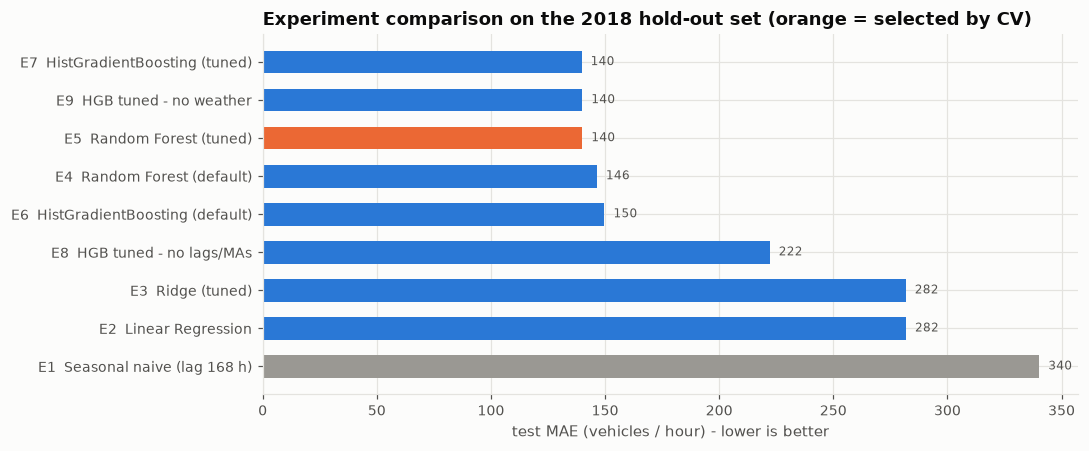

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_df = exp_table.sort_values("test_mae", ascending=False)
best_id = exp_table["cv_mae"].astype(float).idxmin()
colors = [SERIES[1] if i == best_id else (NEUTRAL if i == "E1" else SERIES[0]) for i in plot_df.index]
ax.barh(plot_df.index + "  " + plot_df.model, plot_df.test_mae, color=colors, height=0.6)
for i, v in enumerate(plot_df.test_mae):
    ax.text(v + 4, i, f"{v:.0f}", va="center", fontsize=8, color=TEXT_SECONDARY)
ax.set_xlabel("test MAE (vehicles / hour) - lower is better")
ax.set_title("Experiment comparison on the 2018 hold-out set (orange = selected by CV)")
fig.tight_layout(); save(fig, "m2_experiment_comparison"); plt.show()

## 5. Final model: diagnostics

Selected by lowest CV MAE: E5 - Random Forest (tuned)


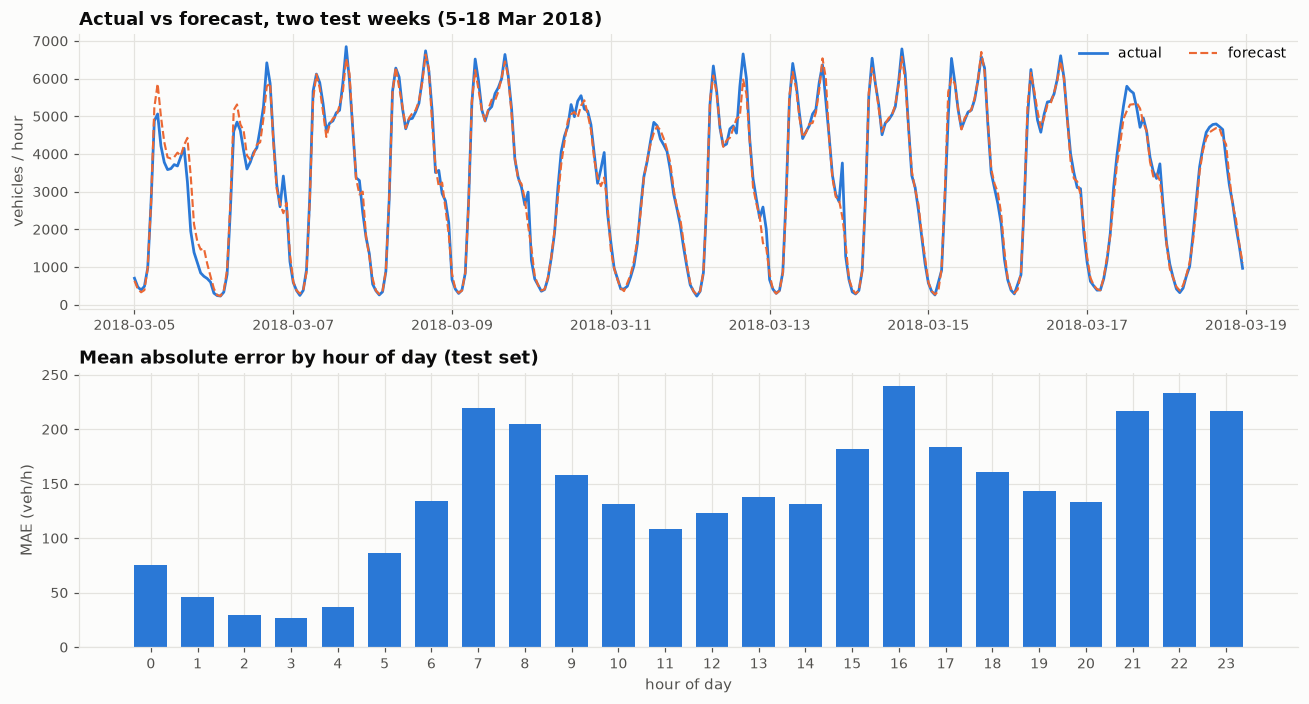

Worst test days by mean absolute error:


,MAE,weekday,snow hours,holiday
date_time,,,,
2018-01-22,424.0,Monday,19,None
2018-04-14,412.0,Saturday,22,None
2018-03-05,411.0,Monday,19,None
2018-05-21,348.0,Monday,0,None
2018-04-03,341.0,Tuesday,23,None


In [15]:
best_id = exp_table["cv_mae"].astype(float).idxmin()
print("Selected by lowest CV MAE:", best_id, "-", exp_table.loc[best_id, "model"])
final_model = hgb_search.best_estimator_ if best_id == "E7" else {"E5": rf_search.best_estimator_, "E6": hgb, "E4": rf}.get(best_id, hgb_search.best_estimator_)
pred = pd.Series(final_model.predict(X_test), index=X_test.index)
resid = y_test - pred

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
week = slice("2018-03-05", "2018-03-18")
axes[0].plot(y_test.loc[week], color=SERIES[0], linewidth=1.8, label="actual")
axes[0].plot(pred.loc[week], color=SERIES[1], linewidth=1.4, linestyle="--", label="forecast")
axes[0].set_title("Actual vs forecast, two test weeks (5-18 Mar 2018)"); axes[0].set_ylabel("vehicles / hour"); axes[0].legend(ncol=2)
by_hour = resid.abs().groupby(resid.index.hour).mean()
axes[1].bar(by_hour.index, by_hour.values, color=SERIES[0], width=0.7)
axes[1].set_title("Mean absolute error by hour of day (test set)"); axes[1].set_xlabel("hour of day"); axes[1].set_ylabel("MAE (veh/h)")
axes[1].set_xticks(range(0, 24))
fig.tight_layout(); save(fig, "m3_forecast_diagnostics"); plt.show()

worst = resid.abs().resample("D").mean().nlargest(5)
print("Worst test days by mean absolute error:")
display(pd.DataFrame({"MAE": worst.round(0),
                      "weekday": [d.day_name() for d in worst.index],
                      "snow hours": [int((test.loc[str(d.date()), "weather_main"] == "Snow").sum()) for d in worst.index],
                      "holiday": [test.loc[str(d.date()), "holiday"].iloc[0] for d in worst.index]}))

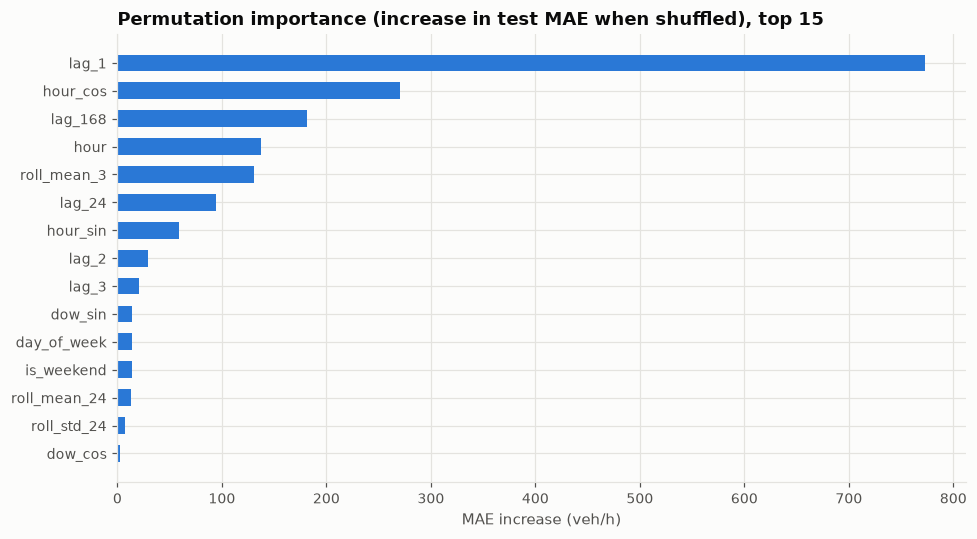

In [16]:
sample = X_test.sample(2000, random_state=RANDOM_STATE)
pi = permutation_importance(final_model, sample, y_test.loc[sample.index], n_repeats=5,
                            random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=SERIES[0], height=0.6)
ax.set_title("Permutation importance (increase in test MAE when shuffled), top 15")
ax.set_xlabel("MAE increase (veh/h)")
fig.tight_layout(); save(fig, "m4_feature_importance"); plt.show()

## 6. Save the model for the API / prediction script

In [17]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, MODEL_PATH, compress=3)

row = exp_table.loc[best_id]
metadata = {
    "experiment": best_id,
    "model": row["model"],
    "estimator": type(final_model).__name__,
    "hyperparameters": final_model.get_params() if not hasattr(final_model, "steps") else str(final_model),
    "features": FEATURES,
    "target": TARGET,
    "horizon": "1 hour ahead",
    "train_period": [str(train.index.min()), str(train.index.max())],
    "test_period": [str(test.index.min()), str(test.index.max())],
    "cv_mae": float(row["cv_mae"]),
    "test_metrics": {k: float(row[k]) for k in ["test_mae", "test_rmse", "test_r2", "test_wape"]},
    "min_history_hours": max(pp.LAGS + pp.ROLLING_WINDOWS) + 1,
    "sklearn_version": sklearn.__version__,
    "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
}
MODEL_METADATA_PATH.write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
print("Saved", MODEL_PATH.name, f"({MODEL_PATH.stat().st_size/1e6:.1f} MB) and", MODEL_METADATA_PATH.name)
print(json.dumps({k: metadata[k] for k in ["experiment", "model", "cv_mae", "test_metrics", "min_history_hours"]}, indent=2))

Saved traffic_model.joblib (34.3 MB) and model_metadata.json
{
  "experiment": "E5",
  "model": "Random Forest (tuned)",
  "cv_mae": 173.8,
  "test_metrics": {
    "test_mae": 140.0,
    "test_rmse": 219.4,
    "test_r2": 0.9876,
    "test_wape": 4.22
  },
  "min_history_hours": 169
}


## 7. Discussion

**Experiment table summary** (full table: `outputs/experiment_results.csv`)

| Exp | Model | CV MAE | Test MAE | Test RMSE | Test R² |
|---|---|---|---|---|---|
| E1 | Seasonal naive (lag 168) | 352.9 | 340.2 | 651.2 | 0.891 |
| E2 | Linear Regression | 295.2 | 281.8 | 397.7 | 0.959 |
| E3 | Ridge, tuned (alpha = 10) | 294.7 | 281.7 | 398.0 | 0.959 |
| E4 | Random Forest, default | 184.4 | 146.4 | 231.4 | 0.986 |
| **E5** | **Random Forest, tuned** | **173.8** | **140.0** | **219.4** | **0.988** |
| E6 | HistGradientBoosting, default | 181.7 | 149.7 | 229.3 | 0.987 |
| E7 | HistGradientBoosting, tuned | 174.5 | 139.7 | 218.1 | 0.988 |
| E8 | E7 without lags / moving averages | 301.4 | 222.1 | 377.4 | 0.963 |
| E9 | E7 without weather | 174.5 | 140.0 | 219.8 | 0.988 |

**What the experiments show**
1. **Every trained model beats the seasonal-naive baseline.** The tuned tree models cut MAE from 340 to **≈140 veh/h (−59%)**, a WAPE of about 4.2%. RMSE falls further, 651 → 219, so large misses are much rarer.
2. **Linear models plateau at MAE ≈ 282.** The hour × weekday × lag interactions (e.g. *a high `lag_1` at 07:00 on a weekday means the peak continues; at 07:00 on a Saturday it does not*) are non-linear. Regularisation does not help: the Ridge grid is flat between alpha = 0.01 and 100.
3. **Hyperparameter tuning helps both tree families.** Random Forest improves from CV MAE 184.4 to 173.8 (−5.7%); the best configuration uses depth-limited trees (`max_depth = 18`), `max_features = 0.33` and `min_samples_leaf = 2`. HistGradientBoosting improves from 181.7 to 174.5 (−4.0%), with a lower learning rate (≈0.03), bigger trees (≈122 leaves) and larger leaves (58 samples). The search table shows learning rates above ≈0.18 are clearly worse (CV MAE ≈186–187).
4. **E5 and E7 are practically tied** (0.4% apart in CV and on test). E5 is selected because the rule set beforehand is *lowest CV MAE*. E7 would be an equally valid choice, and it is about 30× smaller on disk.
5. **Ablations confirm the EDA.** Removing lags and moving averages (E8) raises CV MAE by **73%** (174.5 → 301.4). Without them the model only knows a typical weekly profile and cannot react to the current level (Q3, Q6). Removing weather (E9) changes **almost nothing**. Snow is rare, and its effect shows up in `lag_1` within an hour (Q4: weather is a secondary driver).
6. **Feature importance** agrees: `lag_1`, hour-of-day encodings, `lag_168`, `roll_mean_3` and `lag_24` dominate.

**Where the model fails.** Errors peak at **07:00–08:00 and 16:00** (rush-hour ramps, where one hour can change by thousands of vehicles) and at **21:00–23:00** (evening events). The five worst test days include four **heavy-snow days** (19–23 snowy hours each, e.g. the 14 Apr 2018 snowstorm, with daily volume 64% below the same day last week). On those days lagged traffic only adapts after the drop has started.

**Possible improvements:** a dedicated snow-intensity feature from a weather forecast, event calendars (concerts, games), multi-step horizons (direct or recursive) for planning further ahead, and an LSTM or temporal CNN to compare against the tree models.